# Notizbuch zum Analysieren und verstehen des MNIST HAM10000 Datensatz

**Autoren**
- [1] Noel Codella, Veronica Rotemberg, Philipp Tschandl, M. Emre Celebi, Stephen Dusza, David Gutman, Brian Helba, Aadi Kalloo, Konstantinos Liopyris, Michael Marchetti, Harald Kittler, Allan Halpern: "Skin Lesion Analysis Toward Melanoma Detection 2018: A Challenge Hosted by the International Skin Imaging Collaboration (ISIC)", 2018; https://arxiv.org/abs/1902.03368
- [2] Tschandl, P., Rosendahl, C. & Kittler, H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. Sci. Data 5, 180161 doi:10.1038/sdata.2018.161 (2018).

**Generelle Eckdaten**
- verwendet für den ISIC 2018 Wettkampf 
    - Subziele: Umriss der Hautläsion erkennen, Läsionen-Mekmale feststellen (z.B. gepunktet, Streifen etc.), Labeln von Hautläsionen
- eine Metadaten Datei (`HAM10000_metadata.csv`) mit Spalten `lesion_id`, `image_id`, `dx` (Diagnose), `dx_type` (Diagnose-Methode), `age` (Alter), `sex` (Geschlecht), `localization` (Körperteil)
- zwei Ordner mit Bildrohdaten entsprechend image_id
- 4 .csv Dateien mit komprimierten Pixelrohwerten (sowohl '8x8' als auch '28x28') und `dx`-Label für RGB und HLS (?)

**Diagnose-Typen (`dx`)**
- `nv`: Melanocytic nevi (Melanozytärer Nävus / gewöhnliches Muttermal)
- `mel`: Melanoma (Melanom / schwarzer Hautkrebs)
- `bkl`: Benign keratosis-like lesions (Gutartige Keratose-ähnliche Läsionen)
- `bcc`: Basal cell carcinoma (Basalzellkarzinom)
- `akiec`: Actinic keratoses / Intraepithelial carcinoma (Aktinische Keratose / intraepitheliales Karzinom)
- `vasc`: Vascular lesions (Vaskuläre Läsionen)
- `df`: Dermatofibroma (Dermatofibrom)

**Diagnose-Methoden (`dx_type`)**
- `histo`: Histopathologisch bestätigt (durch Gewebeuntersuchung)
- `follow_up`: Durch Verlaufskontrolle bestätigt
- `consensus`: Durch Expertenkonsens bestätigt
- `confocal`: Durch konfokale Mikroskopie bestätigt

## Imports und dataframe aufbauen

In [11]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns


kagglehub.login()

In [9]:
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", path)

metadata_file = os.path.join(path, "HAM10000_metadata.csv")
df = pd.read_csv(metadata_file)

Path to dataset files: C:\Users\Admin\.cache\kagglehub\datasets\kmader\skin-cancer-mnist-ham10000\versions\2


In [14]:
plt.style.use('seaborn-v0_8-dark')
plt.rcParams['figure.figsize'] = [12, 6]

## Visualisierung der Datensatzmerkmale

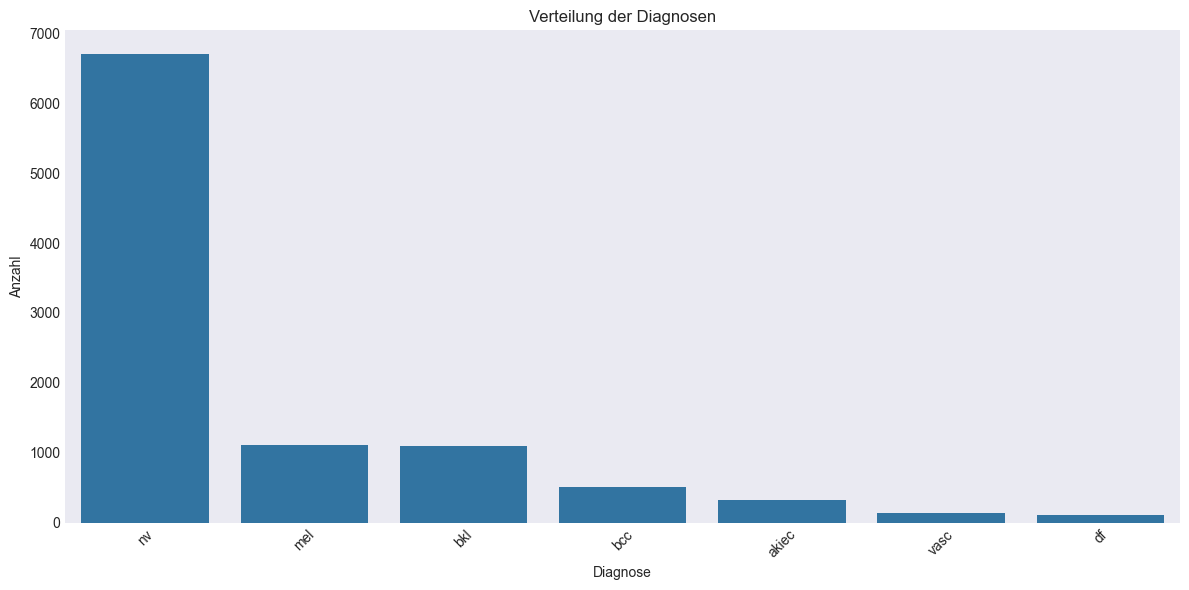

In [15]:
# 1. Verteilung der Diagnosen
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='dx', order=df['dx'].value_counts().index)
plt.title('Verteilung der Diagnosen')
plt.xlabel('Diagnose')
plt.ylabel('Anzahl')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

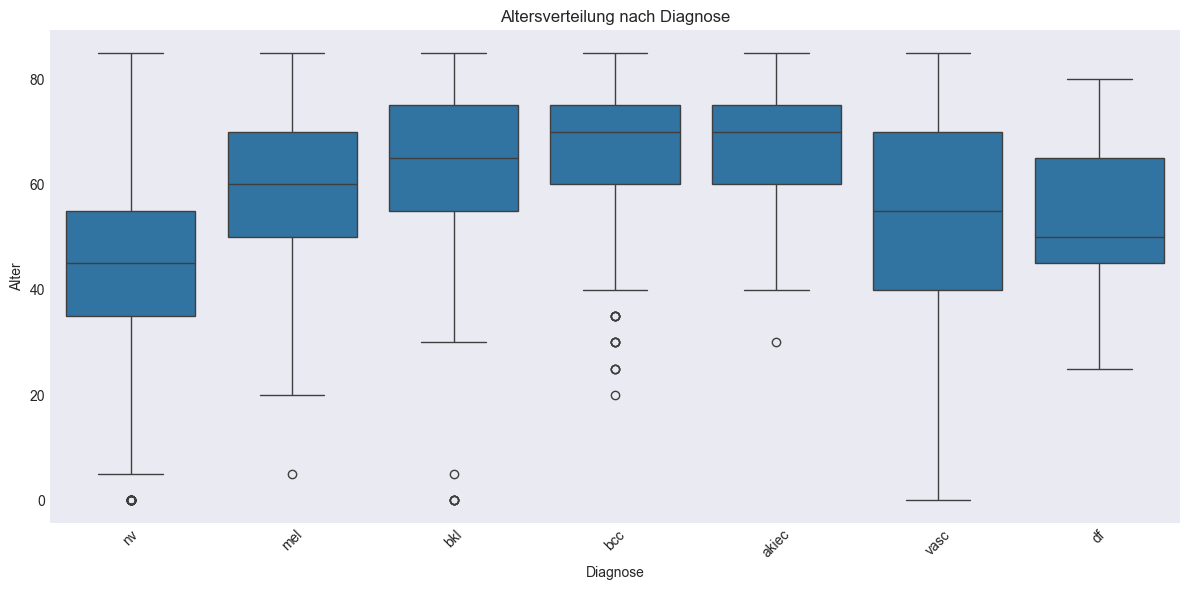

In [16]:
# 2. Altersverteilung nach Diagnose
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='dx', y='age', order=df['dx'].value_counts().index)
plt.title('Altersverteilung nach Diagnose')
plt.xlabel('Diagnose')
plt.ylabel('Alter')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

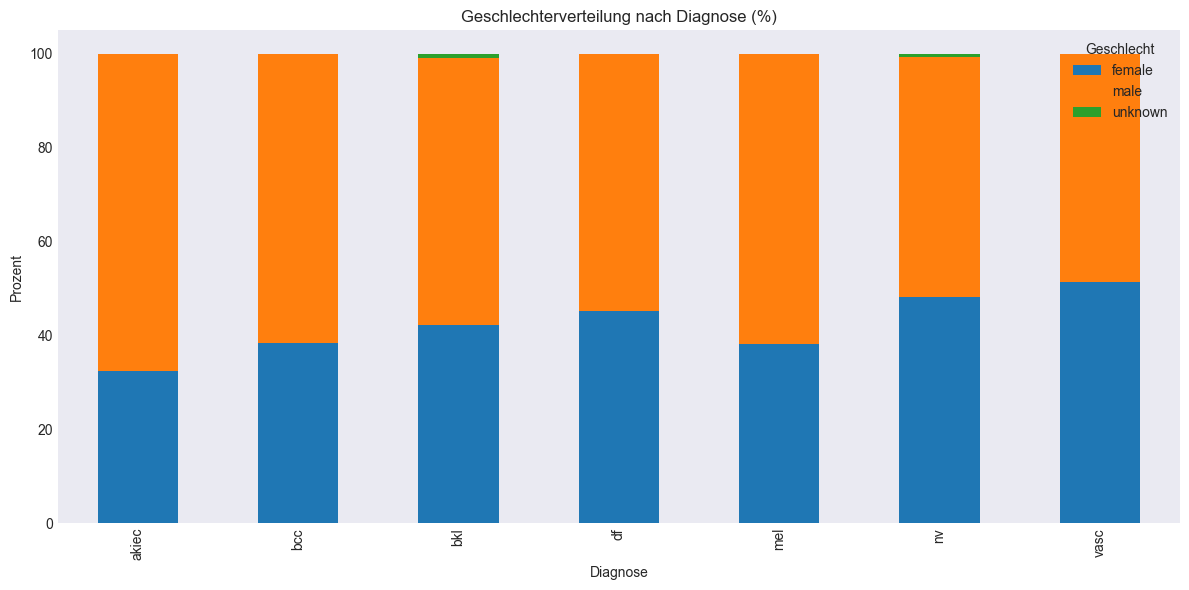

In [17]:
# 3. Geschlechterverteilung nach Diagnose
gender_diag = pd.crosstab(df['dx'], df['sex'], normalize='index') * 100
plt.figure(figsize=(12, 6))
gender_diag.plot(kind='bar', stacked=True)
plt.title('Geschlechterverteilung nach Diagnose (%)')
plt.xlabel('Diagnose')
plt.ylabel('Prozent')
plt.legend(title='Geschlecht')
plt.tight_layout()
plt.show()

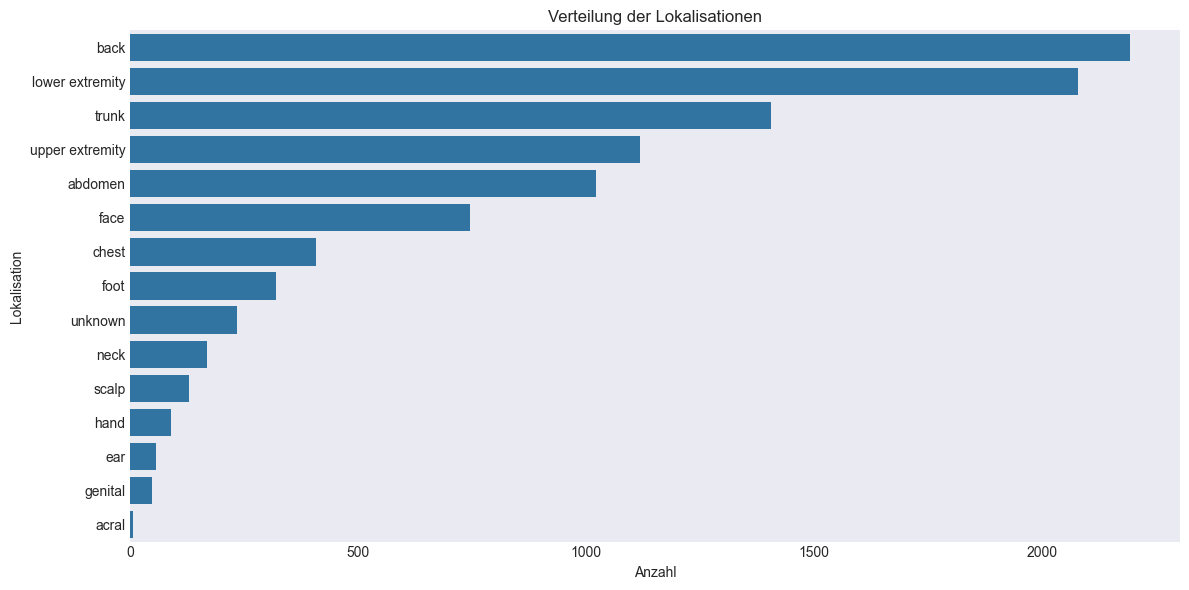

In [18]:
# 4. Verteilung der Lokalisationen
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='localization', order=df['localization'].value_counts().index)
plt.title('Verteilung der Lokalisationen')
plt.xlabel('Anzahl')
plt.ylabel('Lokalisation')
plt.tight_layout()
plt.show()

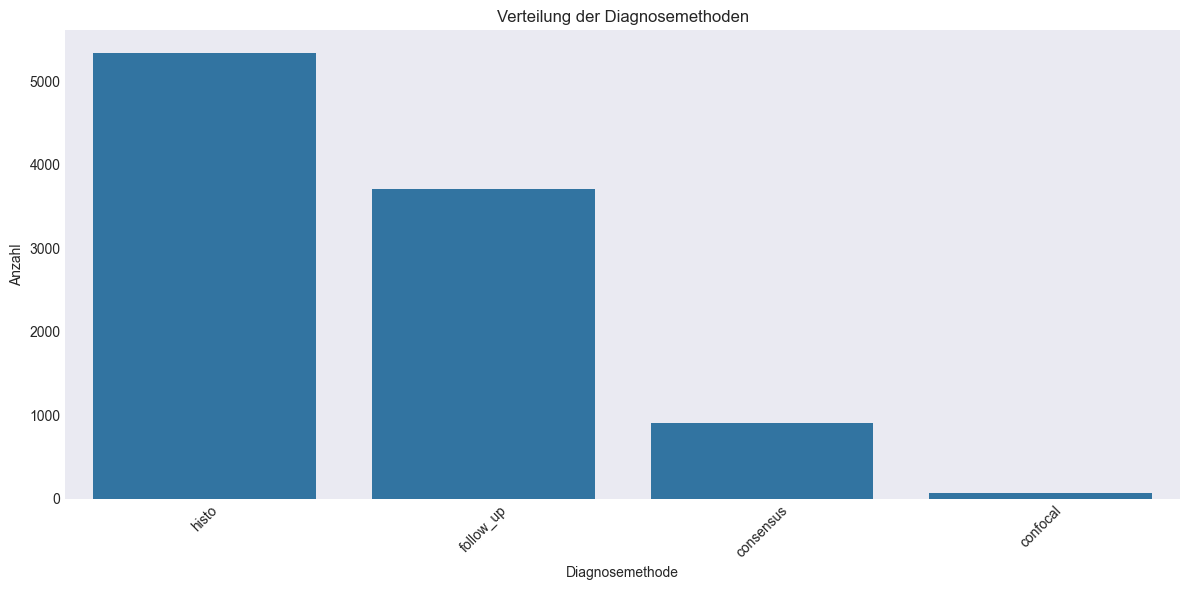

In [19]:
# 5. Verteilung der Diagnosemethoden
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='dx_type', order=df['dx_type'].value_counts().index)
plt.title('Verteilung der Diagnosemethoden')
plt.xlabel('Diagnosemethode')
plt.ylabel('Anzahl')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()